# Phoneme counts: how many phonemes and words for each phoneme you choose

Text → IPA (with the same ɪ → i clean-up as the other notebooks) → counts, for every phoneme in `PHONEMES`:
- **phonemes**: how many times it occurs
- **words**: how many words contain it (each occurrence of a word in the text counts, like `word_quota`), and how many *different* words
- how many words have it once, twice, 3+ times
- how often it is in a **stressed** syllable (vowels)
- which phonemes share words (the overlap that matters for one-change-per-word rules)
- spread over the sentences, the most frequent words, and the text with every match coloured

Matching uses the same scanner as `manipulate()` (longest match, `tʃ ts dʒ dz` protected), so the counts are exactly what a rule on that phoneme would see. Nothing is synthesized.

In [1]:
from functions import text_to_ipa_chunks, one_sentence_chunks, _scan, VOWELS, VOCAB
from word_quota import normalize_ipa, _word_spans
import re, csv, html, os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from collections import Counter, defaultdict
from IPython.display import display, HTML

c:\Users\utente\anaconda3\envs\koko\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\utente\anaconda3\envs\koko\Lib\site-packages\torch\nn\modules\rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  warnings.warn(
c:\Users\utente\anaconda3\envs\koko\Lib\site-packages\torch\nn\utils\weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


## Settings
`PHONEMES`: a phoneme (`"e"`), a multi-character token (`"tʃ"`, `"kʲ"`), or a list counted as **one** class (`["e", "ɛ"]`). Entries are counted independently, so `"e"` and `["e", "ɛ"]` can both be in the list.

In [2]:
text = ("""

Irene Valli lavorava come botanica all'università di Bologna, e da molti anni studiava le piante che crescono vicino al mare. Quell'anno doveva raccogliere alcuni campioni di una piccola pianta con fiori gialli, che cresceva soltanto sulle rocce di un'isola del sud. L'isola si chiamava Calvara, era lunga pochi chilometri e aveva un solo porto, collegato alla costa da un traghetto al giorno. Il traghetto partiva ogni mattina alle sette da Porto Ferrante, una cittadina di pescatori che si trovava alla fine di una lunga linea ferroviaria. Irene aveva preparato il viaggio con attenzione, perché la pianta fioriva soltanto per tre settimane, all'inizio di maggio. Nello zaino aveva messo buste di carta, un quaderno, una piccola pala, una macchina fotografica e una cartina dettagliata dell'isola. Aveva prenotato anche una camera a Porto Ferrante, perché il treno arrivava sempre la sera, dopo la partenza del traghetto.
Il giorno della partenza ha preso il treno a Bologna di primo mattino, e ha cambiato a Roma per continuare verso sud. A Roma ha avuto mezz'ora di tempo, e ha comprato un panino e una bottiglia d'acqua per il resto del viaggio. Il secondo treno era più lento e più vecchio, e si fermava in quasi tutte le stazioni lungo la costa. Nel suo vagone c'erano pochi passeggeri: una coppia di turisti con una grande valigia e un uomo che leggeva il giornale. Dal finestrino si vedevano campi di grano, uliveti e, ogni tanto, una striscia di mare blu dietro le colline. Irene ha passato il viaggio a rileggere i suoi appunti e a controllare sulla cartina i punti dove la pianta era stata trovata. Secondo gli studi precedenti, la pianta cresceva soprattutto sulle rocce della costa nord, esposte al vento e lontane dalle spiagge.
Il treno è arrivato a Porto Ferrante verso le sette di sera, quando il sole era già basso sopra il mare. La stazione era piccola e quasi vuota, con una sola panchina e un orologio fermo da molto tempo sulla stessa ora. Irene ha camminato fino al porto, dove aveva prenotato una camera in una pensione con le finestre sulle barche dei pescatori. Le case erano basse e colorate, e lungo il porto c'erano piccoli negozi che vendevano reti, corde e attrezzi per le barche. La proprietaria della pensione le ha dato la chiave e le ha spiegato dove si comprava il biglietto per il traghetto del mattino. La biglietteria si trovava in una casetta bianca vicino al molo, e apriva mezz'ora prima della partenza della nave. Prima di cena Irene ha fatto una passeggiata sul molo, e da lì ha visto all'orizzonte la sagoma scura dell'isola. Calvara sembrava vicina, ma la proprietaria le aveva detto che il traghetto impiegava quasi due ore per arrivare.
Quella sera il vento ha cominciato a soffiare da nord, prima piano e poi sempre più forte, e le barche nel porto si muovevano molto. Dalla finestra della camera si sentivano soltanto il vento e le corde delle barche che battevano contro gli alberi di legno. Irene è andata a dormire presto, perché voleva essere alla biglietteria alle sei e mezza, prima degli altri passeggeri. Il mattino seguente, quando è arrivata al molo, ha trovato un foglio attaccato alla porta della biglietteria. Sul foglio c'era scritto che il traghetto per Calvara non partiva, a causa del mare agitato e del vento forte. Un impiegato è uscito dalla casetta e ha spiegato ai pochi passeggeri che il traghetto non viaggiava quando le onde superavano i due metri. "Domani il vento dovrebbe calare, ma oggi nessuna nave grande può entrare nel porto dell'isola", ha detto l'impiegato. Gli altri passeggeri, quasi tutti abitanti dell'isola, hanno deciso di aspettare il giorno seguente e sono tornati verso il paese. Irene ha chiesto se esistevano altri modi per arrivare a Calvara nella stessa giornata, anche con un viaggio più lungo. L'impiegato ha pensato per qualche secondo, poi ha detto che sulla costa c'era un altro piccolo porto, più a sud, chiamato Marina di Scoglio. Da lì, a volte, partivano barche private per l'isola, perché il tratto di mare era più corto e più riparato dal vento di nord. Ha aggiunto che un autobus della linea costiera passava davanti al porto alle otto e un quarto, e arrivava a Marina di Scoglio in un'ora. Irene ha ringraziato, ha comprato un biglietto per l'autobus nel bar del porto e si è seduta ad aspettare alla fermata.

L'autobus era piccolo e blu, e alle otto e un quarto si è fermato davanti al porto con una precisione che Irene non si aspettava. A bordo c'erano soltanto un'anziana signora con una borsa della spesa e due operai che andavano a lavorare in un cantiere. L'autista ha spiegato che la linea costiera serviva soprattutto gli studenti e i lavoratori dei paesi più piccoli della zona. La strada correva lungo la costa, a volte proprio sopra il mare e a volte tra campi di fichi d'India e muretti di pietra. Da quella strada l'isola si vedeva sempre a sinistra, e cambiava forma lentamente, man mano che l'autobus scendeva verso sud. In alcuni punti il vento era così forte che l'autista rallentava, e le onde bianche si rompevano contro gli scogli sotto la strada. Irene ha notato che più a sud il mare diventava più calmo, perché la costa formava una grande curva che lo proteggeva dal vento. Il viaggio è durato poco più di un'ora, con fermate in tre paesi costruiti sulle colline sopra il mare.
Marina di Scoglio era un porto molto piccolo, con una decina di barche, un bar e una chiesa bianca sopra una scogliera. Nel bar Irene ha chiesto al barista se qualcuno, quel giorno, portava passeggeri a Calvara con la propria barca. Il barista ha detto che in giornate come quella i pescatori restavano a terra, ma che qualcuno lavorava comunque. Poi ha indicato un uomo seduto a un tavolo vicino alla finestra, che beveva un caffè e controllava qualcosa sul telefono. L'uomo si chiamava Nicola Amato, e trasportava merci e persone tra la costa e l'isola con una barca a motore. Nicola ha ascoltato la richiesta di Irene e ha guardato il mare fuori dalla finestra per un lungo momento. Poi ha spiegato che da Marina di Scoglio il viaggio durava solo quaranta minuti, e che il lato sud dell'isola era protetto dalle onde. "Possiamo partire tra un'ora, quando avrò caricato le casse di frutta per il negozio di Calvara", ha detto Nicola. La frutta era destinata all'unico negozio di alimentari dell'isola, che riceveva le merci tre volte alla settimana.
Nicola ha chiesto a Irene di aiutarlo a portare alcune casse sulla barca, e lei ha accettato senza problemi. Mentre caricavano la frutta, Nicola le ha chiesto perché una botanica volesse andare proprio a Calvara in quella stagione. Irene gli ha raccontato della pianta con i fiori gialli, e gli ha mostrato una fotografia sul suo quaderno. Nicola ha detto di aver visto quei fiori molte volte, soprattutto vicino a una vecchia torre di guardia sulla costa nord. La barca era lunga circa otto metri, con una piccola cabina, due panche di legno e un motore che faceva molto rumore. Nicola ha dato a Irene un giubbotto di salvataggio arancione e le ha mostrato dove sedersi per bagnarsi il meno possibile. Irene ha messo il quaderno dentro una busta di plastica, perché sapeva che durante il viaggio gli spruzzi d'acqua arrivavano dappertutto.
Appena usciti dal porto, la barca ha cominciato a salire e scendere sulle onde lunghe, ma con un ritmo regolare. Nicola teneva il timone con una mano e con l'altra indicava a Irene i punti della costa che conosceva da quando era bambino. A metà strada hanno incontrato un gruppo di delfini, che hanno nuotato accanto alla barca per qualche minuto e poi si sono allontanati. Dopo mezz'ora di viaggio la sagoma dell'isola è diventata più chiara, e Irene ha potuto distinguere le rocce, i campi e le prime case. Più si avvicinavano all'isola, più il mare diventava calmo, perché le colline di Calvara bloccavano il vento di nord. Il porto dell'isola era piccolo, con le case colorate disposte intorno a una piazza e una strada che saliva verso l'interno. Sul molo alcuni uomini aspettavano le casse di frutta, e hanno aiutato Nicola a scaricarle con movimenti rapidi e precisi. Nicola ha spiegato che la torre di guardia si trovava a circa un'ora di cammino dal porto, lungo un sentiero ben segnato. Ha detto anche che sarebbe ripartito per la costa alle cinque, ma che il traghetto grande sarebbe tornato in servizio la mattina dopo. Irene ha deciso di restare sull'isola per la notte, così avrebbe avuto tutto il tempo necessario per il suo lavoro. Ha prenotato una camera nell'unico albergo del paese, ha lasciato lo zaino più pesante alla reception e ha preso solo gli strumenti.

Il sentiero partiva dietro la chiesa del paese e saliva tra campi abbandonati, muretti di pietra e piccoli boschi di pini. Lungo la strada ha incontrato soltanto un contadino con un asino carico di legna, che l'ha salutata con un cenno della mano. Dopo mezz'ora di salita Irene è arrivata sulla cima della collina, da cui si vedevano tutta l'isola e, in lontananza, la costa. Il cielo era sereno, ma il vento portava fino in cima l'odore del sale e il rumore delle onde. Da lì il sentiero scendeva verso nord, dove il vento soffiava ancora forte e il mare era bianco di schiuma. Ogni tanto Irene si fermava per bere un po' d'acqua e per controllare sulla cartina la sua posizione rispetto alla torre. La torre di guardia era una costruzione rotonda di pietra grigia, senza tetto, costruita molti secoli prima per controllare le navi. Intorno alla torre le rocce erano coperte di piccole piante basse, che crescevano nelle fessure dove si raccoglieva un po' di terra.
Irene ha cercato a lungo tra le rocce, camminando con attenzione perché il terreno era irregolare e in alcuni punti scivoloso. Dopo circa venti minuti ha trovato il primo gruppo di fiori gialli, in una fessura riparata dal vento sotto il muro della torre. Ha fotografato le piante da vicino, ha misurato la loro altezza e ha scritto sul quaderno la posizione esatta di ogni gruppo. Poi ha raccolto con la piccola pala alcune piante intere, con le radici e un po' di terra, e le ha messe nelle buste. Su ogni busta ha scritto la data e un numero, che corrispondeva a una riga del suo quaderno. Il suo lavoro richiedeva campioni di zone diverse, perché voleva capire se le piante cambiavano a seconda della distanza dal mare. Per questo motivo ha continuato a cercare lungo la costa, prima verso est e poi verso ovest, seguendo un vecchio sentiero di pescatori. In alcuni punti doveva abbassarsi o sedersi sulle rocce, perché le piante crescevano in fessure molto strette e profonde. Nel pomeriggio aveva trovato sette gruppi di piante, alcuni molto vicini all'acqua e altri più in alto, quasi in cima alla scogliera. Ha notato che le piante più vicine al mare erano più basse e avevano foglie più spesse, forse per proteggersi dal sale. Era un'osservazione interessante, che avrebbe controllato con calma in laboratorio, con gli strumenti di misura dell'università.
Verso le sei il vento ha cominciato a calare, e il mare a nord dell'isola è diventato di nuovo blu. Irene è tornata al paese seguendo lo stesso sentiero, con lo zaino pieno di buste e il quaderno pieno di appunti. In albergo ha sistemato i campioni in una scatola di cartone, che ha lasciato aperta per far circolare l'aria durante la notte. A cena, nella piccola trattoria della piazza, ha incontrato Nicola, che alla fine non era ripartito per la costa. La trattoria offriva soltanto due piatti al giorno, e quella sera c'erano pasta con le alici e pesce al forno. Nicola le ha spiegato che aveva deciso di aspettare il mattino, perché doveva caricare alcune casse vuote da riportare a Marina di Scoglio. Poi le ha chiesto se avesse trovato i fiori, e Irene gli ha raccontato della torre e delle piante vicino al mare. "Allora è stato un viaggio utile, anche se ha dovuto fare il giro più lungo", ha detto Nicola.
La mattina seguente il mare era calmo e il cielo era limpido, e il traghetto grande è arrivato in porto puntuale. Prima di salire a bordo Irene ha salutato Nicola, che stava già caricando le casse vuote sulla sua barca. Sul traghetto ha cercato un posto all'ombra, e ha tenuto la scatola dei campioni sulle ginocchia. Durante la traversata ha guardato l'isola allontanarsi, e ha riconosciuto da lontano la torre di guardia sulla costa nord. A Porto Ferrante ha ripreso il treno verso Roma, e poi quello per Bologna, dove è arrivata a tarda sera. Il giorno dopo ha portato i campioni in laboratorio, ha pulito le radici e ha preparato le piante per le analisi. Nelle settimane successive ha confrontato le misure delle piante vicine al mare con quelle delle piante più lontane. I risultati confermavano la sua osservazione: le foglie diventavano più spesse quando la pianta cresceva più vicino all'acqua salata. Irene ha scritto un breve articolo su questo risultato, e nella descrizione del metodo ha spiegato anche il percorso seguito per arrivare sull'isola.

""")

PHONEMES = ["e", "o", "i",  "t", "k"]
NORMALIZE = {"ɪ": "i"}              # applied to the IPA first ({} to switch off)
PROTECT_AFFRICATES = True           # as in manipulate(): t in tʃ / ts, d in dʒ / dz is not counted
TOP_N = 10                          # most frequent words listed per phoneme
OUT_DIR = "output_online"           # CSV files go here

## Text → IPA

In [3]:
ipa_chunks = normalize_ipa(text_to_ipa_chunks(text), NORMALIZE)
sents = one_sentence_chunks(text)
ortho = [re.findall(r"[^\W\d_]+", s_) for s_ in sents]          # spelling, letters only
spans = [_word_spans(s) for s in ipa_chunks]
mismatch = {ci for ci in range(len(ipa_chunks)) if len(ortho[ci]) != len(spans[ci])}
print(f"{len(ipa_chunks)} sentences, {sum(map(len, spans))} words")
if mismatch:
    print("spelling/IPA word counts differ in sentences", sorted(mismatch), "-> spelling shown as '?' there")

def spelled(ci, wi):
    return ortho[ci][wi] if ci not in mismatch and wi < len(ortho[ci]) else "?"

normalize_ipa: ɪ→i ×230
106 sentences, 2208 words
spelling/IPA word counts differ in sentences [0, 1, 2, 4, 5, 8, 10, 17, 19, 20, 26, 28, 29, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 42, 47, 49, 50, 51, 58, 60, 62, 63, 64, 66, 68, 69, 71, 72, 73, 75, 86, 88, 89, 91, 93, 99, 100, 104, 105] -> spelling shown as '?' there


## Counting

In [4]:
LABELS = ["/".join(p) if isinstance(p, (list, tuple)) else p for p in PHONEMES]
KEYS = {lab: (list(p) if isinstance(p, (list, tuple)) else [p]) for lab, p in zip(LABELS, PHONEMES)}
bad = {lab: [k for k in ks if any(c not in VOCAB for c in k)] for lab, ks in KEYS.items()}
bad = {lab: ks for lab, ks in bad.items() if ks}
assert not bad, f"not in Kokoro's vocab, would never match: {bad}"
IS_VOWEL = {lab: all(len(k) == 1 and k in VOWELS for k in ks) for lab, ks in KEYS.items()}

def is_stressed(s, i, a):
    '''True if the vowel at i is the first vowel after the nearest ˈ in its word (word starts at a).'''
    j = i - 1
    while j >= a:
        if s[j] == "ˈ":
            return True
        if s[j] in VOWELS:
            return False
        j -= 1
    return False

# occ[lab] = list of (chunk, word index, position, stressed)
occ = {}
for lab in LABELS:
    occ[lab] = []
    for ci, s in enumerate(ipa_chunks):
        found = []
        _scan(s, KEYS[lab], lambda k, st, i: (found.append(i), k)[1], "all", PROTECT_AFFRICATES,
              pass_pos=True)
        starts = [a for a, _ in spans[ci]]
        for i in found:
            wi = max(w for w, a in enumerate(starts) if a <= i)
            occ[lab].append((ci, wi, i, is_stressed(s, i, starts[wi]) if IS_VOWEL[lab] else None))

word_ipa = {(ci, wi): ipa_chunks[ci][a:b] for ci in range(len(ipa_chunks)) for wi, (a, b) in enumerate(spans[ci])}
per_word = {lab: Counter((ci, wi) for ci, wi, _, _ in occ[lab]) for lab in LABELS}   # word -> occurrences

summary = []
for lab in LABELS:
    pw = per_word[lab]
    n_ph, n_w = len(occ[lab]), len(pw)
    types = {word_ipa[w] for w in pw}
    dist = Counter(min(c, 3) for c in pw.values())
    st = sum(1 for *_, s_ in occ[lab] if s_) if IS_VOWEL[lab] else None
    summary.append(dict(phoneme=lab, phonemes=n_ph, words=n_w, word_types=len(types),
                        per_word=round(n_ph / n_w, 2) if n_w else 0,
                        w1=dist[1], w2=dist[2], w3plus=dist[3],
                        stressed=st, unstressed=(n_ph - st) if st is not None else None,
                        pct_of_words=round(100 * n_w / sum(map(len, spans)), 1)))

hdr = ["phoneme", "phonemes", "words", "word_types", "per_word", "w1", "w2", "w3plus", "stressed", "unstressed", "pct_of_words"]
print(f"{'':10}{'phonemes':>9}{'words':>7}{'types':>7}{'/word':>7}{'1×':>6}{'2×':>5}{'3+×':>5}{'stress':>8}{'unstr':>7}{'% words':>9}")
for r in summary:
    st = f"{r['stressed']:>8}{r['unstressed']:>7}" if r["stressed"] is not None else f"{'–':>8}{'–':>7}"
    print(f"{r['phoneme']:10}{r['phonemes']:>9}{r['words']:>7}{r['word_types']:>7}{r['per_word']:>7}"
          f"{r['w1']:>6}{r['w2']:>5}{r['w3plus']:>5}{st}{r['pct_of_words']:>8}%")

           phonemes  words  types  /word    1×   2×  3+×  stress  unstr  % words
e               912    819    289   1.11   729   87    3     103    809    37.1%
o               862    728    358   1.18   601  121    6     151    711    33.0%
i               740    676    270   1.09   614   60    2     171    569    30.6%
t               633    541    294   1.17   449   92    0       –      –    24.5%
k               406    393    155   1.03   380   13    0       –      –    17.8%


## 1. Phonemes and words per phoneme

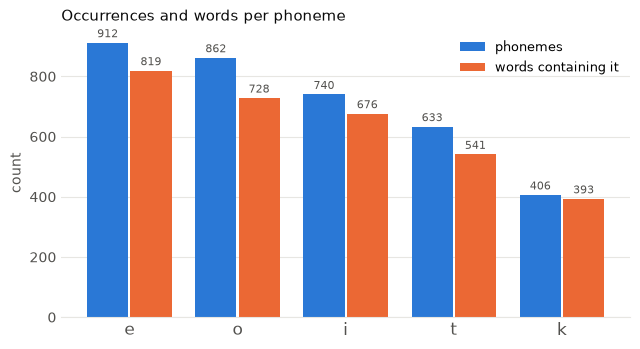

In [5]:
BLUE, ORANGE = "#2a78d6", "#eb6834"          # categorical slots 1 and 2
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e7e6e2"

def style(ax):
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)

x = np.arange(len(LABELS)); w = 0.38
ph = [r["phonemes"] for r in summary]; wd = [r["words"] for r in summary]
fig, ax = plt.subplots(figsize=(max(6, 0.9 * len(LABELS) + 2), 3.6))
b1 = ax.bar(x - w / 2 - 0.01, ph, w, color=BLUE, label="phonemes")
b2 = ax.bar(x + w / 2 + 0.01, wd, w, color=ORANGE, label="words containing it")
for bars in (b1, b2):
    ax.bar_label(bars, padding=2, fontsize=8, color=MUTED)
ax.set_xticks(x, LABELS, fontsize=12, color=INK)
ax.set_ylabel("count", color=MUTED)
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.set_title("Occurrences and words per phoneme", loc="left", color=INK, fontsize=11)
style(ax); plt.tight_layout(); plt.show()

## 2. How many times per word
Words split by how often they contain the phoneme. Relevant for `word_quota` with a `phonemes` target: the more 2× / 3+ words, the further the phoneme count can be pushed above the word count.

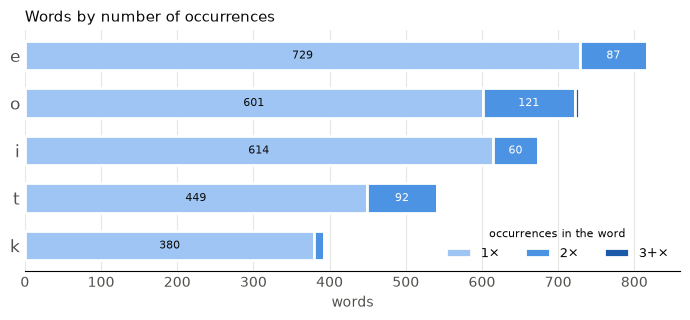

In [6]:
SEQ = ["#9ec5f3", "#4c93e3", "#1b5aa8"]       # one hue, light -> dark: 1×, 2×, 3+×
fig, ax = plt.subplots(figsize=(7, 0.42 * len(LABELS) + 1.2))
y = np.arange(len(LABELS))[::-1]
left = np.zeros(len(LABELS))
for key, lab, c in (("w1", "1×", SEQ[0]), ("w2", "2×", SEQ[1]), ("w3plus", "3+×", SEQ[2])):
    v = np.array([r[key] for r in summary])
    ax.barh(y, v, left=left, color=c, edgecolor="white", linewidth=2, label=lab, height=0.62)
    for yi, l, vi in zip(y, left, v):
        if vi >= max(left.max() + v.max(), 1) * 0.04:
            ax.text(l + vi / 2, yi, str(vi), ha="center", va="center", fontsize=8,
                    color="white" if c != SEQ[0] else INK)
    left += v
ax.set_yticks(y, LABELS, fontsize=12, color=INK)
ax.set_xlabel("words", color=MUTED)
ax.legend(frameon=False, ncol=3, loc="lower right", fontsize=9, title="occurrences in the word", title_fontsize=8)
ax.set_title("Words by number of occurrences", loc="left", color=INK, fontsize=11)
ax.spines[["top", "right", "left"]].set_visible(False); ax.tick_params(colors=MUTED, length=0)
ax.xaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

## 3. Stressed vs unstressed (vowels)

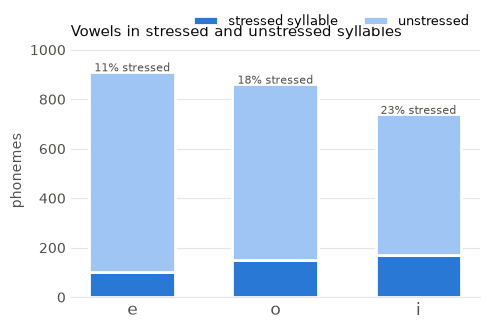

stressed = first vowel after a ˈ mark in the same word


In [7]:
vl = [r for r in summary if r["stressed"] is not None]
if vl:
    fig, ax = plt.subplots(figsize=(max(5, 0.9 * len(vl) + 2), 3.4))
    xx = np.arange(len(vl))
    s_ = np.array([r["stressed"] for r in vl]); u_ = np.array([r["unstressed"] for r in vl])
    ax.bar(xx, s_, 0.6, color=BLUE, edgecolor="white", linewidth=2, label="stressed syllable")
    ax.bar(xx, u_, 0.6, bottom=s_, color="#9ec5f3", edgecolor="white", linewidth=2, label="unstressed")
    for xi, a_, b_ in zip(xx, s_, u_):
        ax.text(xi, a_ + b_ + 1, f"{100 * a_ / max(a_ + b_, 1):.0f}% stressed", ha="center", fontsize=8, color=MUTED)
    ax.set_xticks(xx, [r["phoneme"] for r in vl], fontsize=12, color=INK)
    ax.set_ylabel("phonemes", color=MUTED)
    ax.legend(frameon=False, fontsize=9, ncol=2, loc="lower right", bbox_to_anchor=(1, 1.02))
    ax.set_ylim(0, (s_ + u_).max() * 1.12)
    ax.set_title("Vowels in stressed and unstressed syllables", loc="left", color=INK, fontsize=11)
    style(ax); plt.tight_layout(); plt.show()
    print("stressed = first vowel after a ˈ mark in the same word")
else:
    print("no vowel entries in PHONEMES")

## 4. Shared words
Cell = number of words that contain **both** phonemes; the diagonal = words containing that phoneme. With one change per word, a large overlap means the two phonemes compete for the same words.

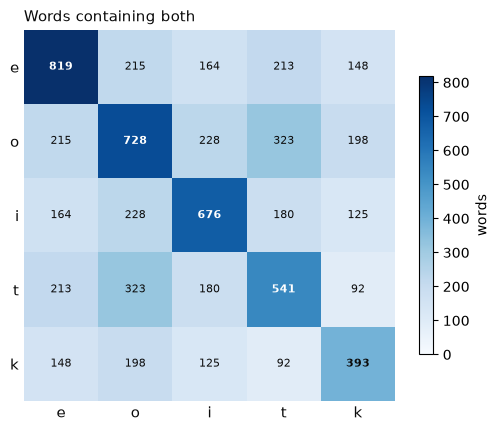

In [8]:
n = len(LABELS)
M = np.array([[len(set(per_word[a]) & set(per_word[b])) for b in LABELS] for a in LABELS])
fig, ax = plt.subplots(figsize=(0.62 * n + 2.2, 0.55 * n + 1.6))
im = ax.imshow(M, cmap="Blues", vmin=0)
for i in range(n):
    for j in range(n):
        ax.text(j, i, M[i, j], ha="center", va="center", fontsize=8,
                color="white" if M[i, j] > 0.55 * M.max() else INK, fontweight="bold" if i == j else None)
ax.set_xticks(range(n), LABELS, fontsize=11); ax.set_yticks(range(n), LABELS, fontsize=11)
ax.tick_params(length=0, colors=INK); [sp.set_visible(False) for sp in ax.spines.values()]
ax.set_title("Words containing both", loc="left", color=INK, fontsize=11)
plt.colorbar(im, ax=ax, shrink=0.75, label="words"); plt.tight_layout(); plt.show()

## 5. Spread over the sentences

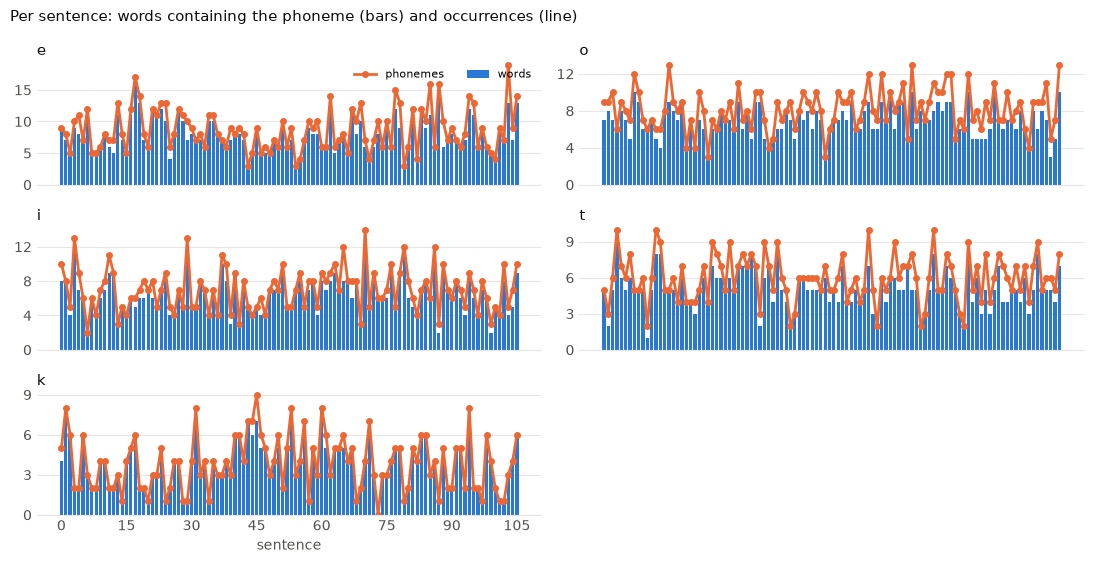

In [9]:
nS = len(ipa_chunks)
words_per_sent = np.array([len(s) for s in spans])
cols = 2 if n > 1 else 1
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(11, 1.7 * rows + 0.6), sharex=True, squeeze=False)
for k, lab in enumerate(LABELS):
    ax = axes[k // cols][k % cols]
    pw = Counter(ci for ci, wi in per_word[lab])
    pp = Counter(ci for ci, *_ in occ[lab])
    ax.bar(range(nS), [pw[c] for c in range(nS)], color=BLUE, width=0.75, label="words")
    ax.plot(range(nS), [pp[c] for c in range(nS)], color=ORANGE, lw=2, marker="o", ms=4, label="phonemes")
    ax.set_title(lab, loc="left", fontsize=11, color=INK, pad=2)
    style(ax)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    if k == 0:
        ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper right")
for k in range(n, rows * cols):
    axes[k // cols][k % cols].axis("off")
for ax in axes[-1]:
    ax.set_xlabel("sentence", color=MUTED)
fig.suptitle("Per sentence: words containing the phoneme (bars) and occurrences (line)", x=0.01, ha="left",
             fontsize=11, color=INK)
plt.tight_layout(); plt.show()

## 6. Most frequent words per phoneme

In [10]:
for lab in LABELS:
    types = Counter()
    spell = defaultdict(Counter)
    for (ci, wi), c in per_word[lab].items():
        wd = word_ipa[(ci, wi)]
        types[wd] += 1
        spell[wd][spelled(ci, wi).lower()] += 1
    top = types.most_common(TOP_N)
    print(f"{lab:7} " + ", ".join(f"{spell[w].most_common(1)[0][0]} /{w}/ ×{c}" for w, c in top))

e       ? /e/ ×100, le /le/ ×42, ? /ke/ ×41, ? /per/ ×28, irene /irˈɛne/ ×26, della /dˌella/ ×18, mare /mˈare/ ×17, piante /pjˈante/ ×12, ? /del/ ×12, perché /perkˌe/ ×12
o       ? /kon/ ×29, ? /pˈɔrto/ ×18, nicola /nikˈola/ ×14, ? /vˈɛnto/ ×13, traghetto /traɡˈetːo/ ×10, verso /vˌɛrso/ ×10, lungo /lˈuŋɡo/ ×10, ? /vjˈaʤːo/ ×9, ? /dellˈizola/ ×9, detto /dˈetːo/ ×8
i       ? /di/ ×68, il /il/ ×67, irene /irˈɛne/ ×26, ? /in/ ×23, ? /si/ ×20, nicola /nikˈola/ ×14, i /i/ ×12, ? /ʎi/ ×11, ? /dellˈizola/ ×9, poi /pˈɔi/ ×9
t       ? /pˈɔrto/ ×18, ? /kˈɔsta/ ×14, ? /vˈɛnto/ ×13, piante /pjˈante/ ×12, traghetto /traɡˈetːo/ ×10, detto /dˈetːo/ ×8, torre /tˈorɾe/ ×8, ? /spjeɡˈato/ ×7, ? /pjˈanta/ ×6, ? /soltˈanto/ ×6
k       ? /ke/ ×41, ? /kon/ ×29, ? /kˈɔsta/ ×14, nicola /nikˈola/ ×14, perché /perkˌe/ ×12, ? /kalvˈaɾa/ ×8, barca /bˈarka/ ×7, ? /alkˌʊni/ ×6, piccola /pˈikːola/ ×6, quaderno /kwadˈɛrno/ ×6


## 7. The text with every match coloured

In [11]:
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SHOW = st_labels = [lab for lab in LABELS if len(KEYS[lab]) == 1][:len(PAL)]   # single phonemes only, max 8
col = {lab: PAL[i] for i, lab in enumerate(SHOW)}
mark = [dict() for _ in ipa_chunks]                       # chunk -> {pos: (label, length)}
for lab in SHOW:
    for ci, wi, i, s_ in occ[lab]:
        mark[ci][i] = (lab, len(KEYS[lab][0]), s_)

def render(ci):
    s, out, j = ipa_chunks[ci], [], 0
    while j < len(s):
        if j in mark[ci]:
            lab, L, s_ = mark[ci][j]
            out.append(f'<b style="color:{col[lab]};{"text-decoration:underline;" if s_ else ""}">{html.escape(s[j:j+L])}</b>')
            j += L
        else:
            out.append(html.escape(s[j])); j += 1
    return (f'<div style="margin:0 0 10px"><div style="color:#888;font-size:11px">sentence {ci}</div>'
            f'<div style="font-size:13px">{html.escape(sents[ci])}</div>'
            f'<div style="font-family:monospace;font-size:14px;color:#333">{"".join(out)}</div></div>')

legend = " ".join(f'<b style="color:{col[l]}">{html.escape(l)}</b>' for l in SHOW)
display(HTML(f'<div style="font-family:system-ui;max-width:1000px">{legend} '
             f'<span style="color:#888">(underlined = stressed)</span><hr>'
             + "".join(render(ci) for ci in range(len(ipa_chunks))) + "</div>"))

## 8. Save the counts

In [12]:
os.makedirs(OUT_DIR, exist_ok=True)
with open(os.path.join(OUT_DIR, "phoneme_counts.csv"), "w", newline="", encoding="utf-8") as f:
    wr = csv.DictWriter(f, fieldnames=hdr); wr.writeheader(); wr.writerows(summary)
with open(os.path.join(OUT_DIR, "phoneme_words.csv"), "w", newline="", encoding="utf-8") as f:
    wr = csv.writer(f)
    wr.writerow(["phoneme", "sentence", "word_index", "spelling", "ipa", "occurrences", "stressed_occurrences"])
    for lab in LABELS:
        st = Counter((ci, wi) for ci, wi, _, s_ in occ[lab] if s_)
        for (ci, wi), c in sorted(per_word[lab].items()):
            wr.writerow([lab, ci, wi, spelled(ci, wi), word_ipa[(ci, wi)], c, st[(ci, wi)] if IS_VOWEL[lab] else ""])
print("written:", os.path.join(OUT_DIR, "phoneme_counts.csv"), "and", os.path.join(OUT_DIR, "phoneme_words.csv"))

written: output_online\phoneme_counts.csv and output_online\phoneme_words.csv
